# Customer Churn Prediction — Data Understanding, Statistical Analysis & Baseline Model

**Dataset:** IBM Telco Customer Churn (7,043 customers in the standard sample). **Goal:** explore churn patterns, build a reproducible logistic-regression baseline, and illustrate retention targeting under explicit assumptions.

**Important:** Observational associations are not causal effects; a churn score alone cannot estimate the impact of a retention offer. The test set is reserved for the final model evaluation.

## 1. Load and inspect the original data
The CSV path is resolved relative to the notebook or project root. Keep the original data unchanged.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np

candidates = [Path('../data/Telco-Customer-Churn.csv'), Path('../data/Telco-Customer-churn.csv'), Path('data/Telco-Customer-Churn.csv'), Path('data/Telco-Customer-churn.csv')]
data_path = next((p for p in candidates if p.exists()), None)
if data_path is None:
    raise FileNotFoundError('Put Telco-Customer-Churn.csv in the project data/ directory.')
df = pd.read_csv(data_path)
print('File:', data_path, 'Shape:', df.shape)
assert {'customerID', 'Churn', 'TotalCharges', 'Contract', 'tenure'}.issubset(df.columns)
display(df.head())

File: ..\data\Telco-Customer-Churn.csv Shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [3]:
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
customerID,7043,7043,7590-VHVEG,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gender,7043,2,Male,3555,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SeniorCitizen,7043.0,NaN,NaN,NaN,0.162147,0.368612,0.0,0.0,0.0,0.0,1.0
Partner,7043,2,No,3641,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Dependents,7043,2,No,4933,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tenure,7043.0,NaN,NaN,NaN,32.371149,24.559481,0.0,9.0,29.0,55.0,72.0
PhoneService,7043,2,Yes,6361,NaN,NaN,NaN,NaN,NaN,NaN,NaN
MultipleLines,7043,3,No,3390,NaN,NaN,NaN,NaN,NaN,NaN,NaN
InternetService,7043,3,Fiber optic,3096,NaN,NaN,NaN,NaN,NaN,NaN,NaN
OnlineSecurity,7043,3,No,3498,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [4]:
# Check missing values
print("Missing values:")
print(df.isnull().sum())

# Check duplicate customers
print("\nDuplicate customer IDs:")
print(df["customerID"].duplicated().sum())

# Check missing or blank TotalCharges
print("\nBlank TotalCharges:")
print(df["TotalCharges"].astype(str).str.strip().eq("").sum())

# Check target distribution
print("\nChurn distribution:")
print(df["Churn"].value_counts())

Missing values:
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

Duplicate customer IDs:
0

Blank TotalCharges:
11

Churn distribution:
Churn
No     5174
Yes    1869
Name: count, dtype: int64


In [5]:
# Identify invalid TotalCharges values
charges = pd.to_numeric(df["TotalCharges"], errors="coerce")

print("Invalid TotalCharges:", charges.isna().sum())
print("Duplicate customer IDs:", df["customerID"].duplicated().sum())

# Display affected records
display(df.loc[charges.isna(),
               ["customerID", "tenure", "MonthlyCharges", "TotalCharges"]])

Invalid TotalCharges: 11
Duplicate customer IDs: 0


,customerID,tenure,MonthlyCharges,TotalCharges
488,4472-LVYGI,0,52.55,
753,3115-CZMZD,0,20.25,
936,5709-LVOEQ,0,80.85,
1082,4367-NUYAO,0,25.75,
1340,1371-DWPAZ,0,56.05,
3331,7644-OMVMY,0,19.85,
3826,3213-VVOLG,0,25.35,
4380,2520-SGTTA,0,20.00,
5218,2923-ARZLG,0,19.70,
6670,4075-WKNIU,0,73.35,


## 2. Data cleaning and validation
`TotalCharges` contains blank strings that appear as invalid numeric values. In the standard data these correspond to tenure zero. The initial EDA assumption is that an unbilled customer has zero total charges; this assumption must be revisited if billing definitions differ.

In [6]:
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
missing_charges = df['TotalCharges'].isna()
print('Invalid TotalCharges:', int(missing_charges.sum()))
print('Tenure distribution among invalid entries:')
print(df.loc[missing_charges, 'tenure'].value_counts(dropna=False))
assert (df.loc[missing_charges, 'tenure'] == 0).all(), 'Inspect missing values with nonzero tenure before filling'
df.loc[missing_charges, 'TotalCharges'] = 0.0
assert df['customerID'].is_unique, 'Duplicate customer identifiers found'
print('Remaining missing TotalCharges:', df['TotalCharges'].isna().sum())

Invalid TotalCharges: 11
Tenure distribution among invalid entries:
tenure
0    11
Name: count, dtype: int64
Remaining missing TotalCharges: 0


## 3. Exploratory analysis: tenure and contracts
These plots compare observed rates within this sample; they do not demonstrate that tenure or contract type causes churn.

In [7]:
df["TenureGroup"] = pd.cut(
    df["tenure"],
    bins=[-1, 12, 24, 48, 72],
    labels=["0–12 months", "13–24 months",
            "25–48 months", "49–72 months"]
)

tenure_churn = (
    df.groupby("TenureGroup", observed=True)["Churn"]
      .agg(
          TotalCustomers="count",
          Churned=lambda x: (x == "Yes").sum()
      )
)

tenure_churn["ChurnRate"] = (
    tenure_churn["Churned"]
    / tenure_churn["TotalCustomers"] * 100
)

display(tenure_churn.round(2))

,TotalCustomers,Churned,ChurnRate
TenureGroup,,,
0–12 months,2186,1037,47.44
13–24 months,1024,294,28.71
25–48 months,1594,325,20.39
49–72 months,2239,213,9.51


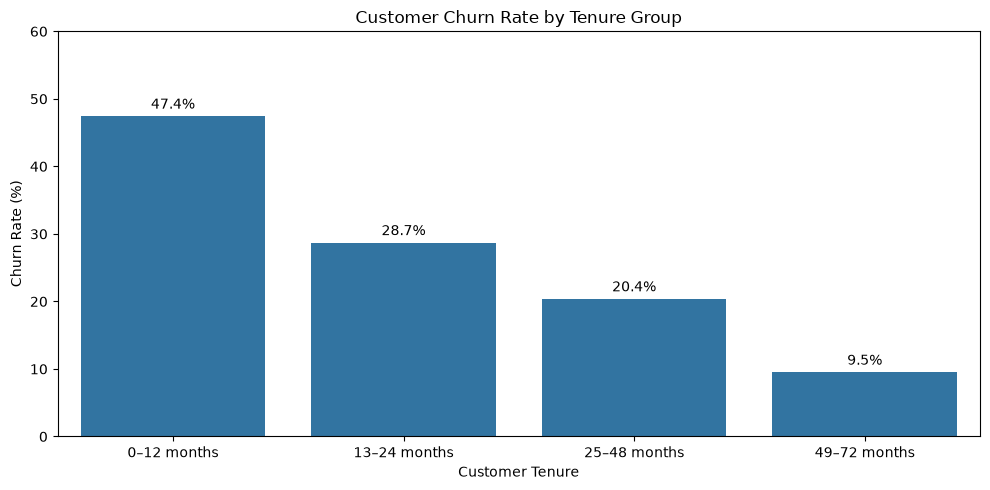

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 5))

ax = sns.barplot(
    data=tenure_churn.reset_index(),
    x="TenureGroup",
    y="ChurnRate"
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", padding=3)

plt.title("Customer Churn Rate by Tenure Group")
plt.xlabel("Customer Tenure")
plt.ylabel("Churn Rate (%)")
plt.ylim(0, 60)

plt.tight_layout()
plt.show()

In [9]:
contract_churn = (
    df.groupby("Contract")["Churn"]
    .agg(
        TotalCustomers="count",
        Churned=lambda x: (x == "Yes").sum()
    )
)

contract_churn["ChurnRate"] = (
    contract_churn["Churned"]
    / contract_churn["TotalCustomers"] * 100
)

display(contract_churn.round(2))

,TotalCustomers,Churned,ChurnRate
Contract,,,
Month-to-month,3875,1655,42.71
One year,1473,166,11.27
Two year,1695,48,2.83


In [10]:
# Chi-square Test: Contract vs Churn
from scipy.stats import chi2_contingency

# Create contingency table
contingency = pd.crosstab(df["Contract"], df["Churn"])

display(contingency)

# Perform Chi-square test
chi2, p_value, dof, expected = chi2_contingency(contingency)

print("Chi-square statistic:", round(chi2, 4))
print("P-value:", p_value)
print("Degrees of freedom:", dof)

Churn,No,Yes
Contract,,
Month-to-month,2220,1655
One year,1307,166
Two year,1647,48


Chi-square statistic: 1184.5966
P-value: 5.863038300673391e-258
Degrees of freedom: 2


In [11]:
# Measure association strength using Cramér's V
n = contingency.to_numpy().sum()
r, c = contingency.shape

cramers_v = np.sqrt(
    chi2 / (n * min(r - 1, c - 1))
)

print("Cramér's V:", round(cramers_v, 4))

Cramér's V: 0.4101


In [12]:
# Calculate Risk Difference by Contract Type
risk_monthly = (
    df.loc[df["Contract"] == "Month-to-month", "Churn"]
    .eq("Yes")
    .mean()
)

risk_two_year = (
    df.loc[df["Contract"] == "Two year", "Churn"]
    .eq("Yes")
    .mean()
)

risk_difference = risk_monthly - risk_two_year

print(f"Monthly churn risk: {risk_monthly:.2%}")
print(f"Two-year churn risk: {risk_two_year:.2%}")
print(f"Risk difference: {risk_difference:.2%}")

Monthly churn risk: 42.71%
Two-year churn risk: 2.83%
Risk difference: 39.88%


In [13]:
# Relative Risk (RR)
relative_risk = risk_monthly / risk_two_year

print(f"Monthly churn risk: {risk_monthly:.2%}")
print(f"Two-year churn risk: {risk_two_year:.2%}")
print(f"Relative Risk: {relative_risk:.2f}")

Monthly churn risk: 42.71%
Two-year churn risk: 2.83%
Relative Risk: 15.08


In [14]:
# Relative Risk vs Odds Ratio
relative_risk = risk_monthly / risk_two_year

odds_monthly = risk_monthly / (1 - risk_monthly)
odds_two_year = risk_two_year / (1 - risk_two_year)

odds_ratio = odds_monthly / odds_two_year

print(f"Relative Risk: {relative_risk:.2f}")
print(f"Odds Ratio: {odds_ratio:.2f}")

Relative Risk: 15.08
Odds Ratio: 25.58


**Statistical interpretation:** A Chi-square p-value tests evidence against independence. Cramér’s V describes association strength; risk difference compares absolute rates, while relative risk and odds ratio compare multiplicative risk/odds. These are descriptive results, not estimated treatment effects.

In [15]:
example_beta = 1.2
example_coefficient_odds_ratio = np.exp(example_beta)
print(f'Illustrative log-odds coefficient: {example_beta}; corresponding odds ratio: {example_coefficient_odds_ratio:.3f}')
print(f'Observed contract odds ratio (unadjusted): {odds_ratio:.3f}')

Illustrative log-odds coefficient: 1.2; corresponding odds ratio: 3.320
Observed contract odds ratio (unadjusted): 25.580


## 4. Prepare modeling data
Use `customerID` only as an identifier, and exclude the target and the EDA-derived `TenureGroup`. Although `SeniorCitizen` is numerically coded, it represents a category and will be one-hot encoded.

In [16]:
y = df['Churn'].map({'No': 0, 'Yes': 1})
X = df.drop(columns=['Churn', 'customerID', 'TenureGroup'], errors='ignore').copy()
assert y.notna().all(), 'Unexpected target labels'
print('Features:', X.shape, 'Target:', y.shape)
print('Churn prevalence:', round(y.mean(), 4))

Features: (7043, 19) Target: (7043,)
Churn prevalence: 0.2654


## 5. Split data before fitting preprocessing
A stratified 20% test split is held back. The remaining data is split into training and validation sets. The validation data is used for model and threshold decisions; the test data is used once for final reporting.

In [17]:
from sklearn.model_selection import train_test_split
X_trainval, X_test, y_trainval, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=42)
X_train, X_val, y_train, y_val = train_test_split(X_trainval, y_trainval, test_size=0.25, stratify=y_trainval, random_state=42)
for label, data, target in [('Train', X_train,y_train),('Validation',X_val,y_val),('Test',X_test,y_test)]:
    print(label, data.shape, f'churn rate={target.mean():.2%}')

Train (4225, 19) churn rate=26.53%
Validation (1409, 19) churn rate=26.54%
Test (1409, 19) churn rate=26.54%


## 6. Leakage-safe preprocessing and models
Missing-value imputation, scaling, and encoding are fitted inside pipelines on training data only. Compare Logistic Regression with a Random Forest baseline using validation ROC-AUC and average precision.

In [18]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, average_precision_score

numeric_features = ['tenure', 'MonthlyCharges', 'TotalCharges']
categorical_features = [col for col in X.columns if col not in numeric_features]
preprocessor = ColumnTransformer([
    ('num', Pipeline([('imputer', SimpleImputer(strategy='median')),('scaler',StandardScaler())]), numeric_features),
    ('cat', Pipeline([('imputer',SimpleImputer(strategy='most_frequent')),('onehot',OneHotEncoder(handle_unknown='ignore'))]),categorical_features)
])
models = {
    'Logistic Regression': LogisticRegression(max_iter=2000, random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=250, min_samples_leaf=5, random_state=42, n_jobs=-1)
}
fitted = {}
comparison = []
for name, estimator in models.items():
    pipe = Pipeline([('preprocessor', preprocessor), ('classifier', estimator)])
    pipe.fit(X_train,y_train)
    probs = pipe.predict_proba(X_val)[:,1]
    comparison.append({'Model':name, 'Validation ROC-AUC':roc_auc_score(y_val,probs), 'Validation PR-AUC':average_precision_score(y_val,probs)})
    fitted[name] = pipe
comparison_df=pd.DataFrame(comparison).sort_values('Validation ROC-AUC', ascending=False)
display(comparison_df.round(4))
selected_name = comparison_df.iloc[0]['Model']
selected_model = fitted[selected_name]
print('Selected using validation ROC-AUC:', selected_name)

,Model,Validation ROC-AUC,Validation PR-AUC
0,Logistic Regression,0.8360,0.6424
1,Random Forest,0.8348,0.6344


Selected using validation ROC-AUC: Logistic Regression


## 7. Choose a threshold on validation data
This uses the validation set for a demonstrative F1-based operating point. In a real retention deployment, choose a threshold using measured campaign costs, lift, capacity, and validation of probability calibration—not test-set optimization.

In [19]:
from sklearn.metrics import precision_score, recall_score, f1_score
val_probs=selected_model.predict_proba(X_val)[:,1]
threshold_rows=[]
for threshold in np.arange(0.20,0.81,0.05):
    pred=(val_probs>=threshold).astype(int)
    threshold_rows.append({'Threshold':round(float(threshold),2),'Precision':precision_score(y_val,pred,zero_division=0),'Recall':recall_score(y_val,pred,zero_division=0),'F1':f1_score(y_val,pred,zero_division=0),'Targeted':int(pred.sum())})
threshold_df=pd.DataFrame(threshold_rows)
display(threshold_df.round(3))
selected_threshold=float(threshold_df.loc[threshold_df['F1'].idxmax(),'Threshold'])
print('Validation-selected F1 threshold:',selected_threshold)

,Threshold,Precision,Recall,F1,Targeted
0,0.20,0.465,0.837,0.598,673
1,0.25,0.507,0.802,0.621,592
2,0.30,0.538,0.751,0.627,522
3,0.35,0.567,0.706,0.629,466
4,0.40,0.595,0.644,0.619,405
5,0.45,0.633,0.591,0.611,349
6,0.50,0.658,0.535,0.590,304
7,0.55,0.688,0.484,0.568,263
8,0.60,0.709,0.377,0.492,199
9,0.65,0.745,0.273,0.399,137


Validation-selected F1 threshold: 0.35


## 8. Final held-out test evaluation
Do not revisit model selection or threshold after observing this evaluation. Metrics describe classification and ranking performance on this held-out sample; they do not establish future calibration or treatment effectiveness.

Final held-out test metrics: {'accuracy': 0.7672, 'precision': 0.5473, 'recall': 0.7112, 'f1': 0.6186, 'roc_auc': 0.843, 'pr_auc': 0.6345}
              precision    recall  f1-score   support

           0       0.88      0.79      0.83      1035
           1       0.55      0.71      0.62       374

    accuracy                           0.77      1409
   macro avg       0.72      0.75      0.73      1409
weighted avg       0.79      0.77      0.78      1409



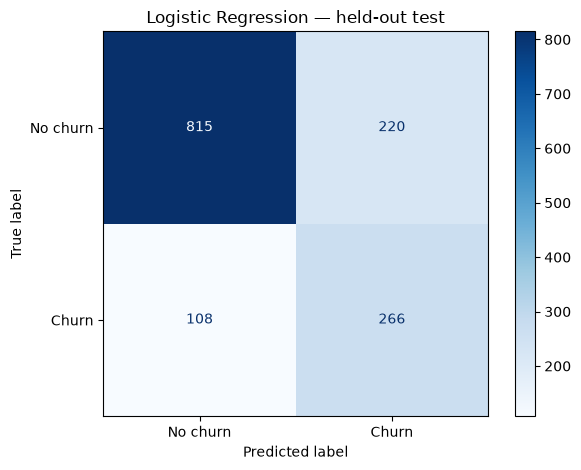

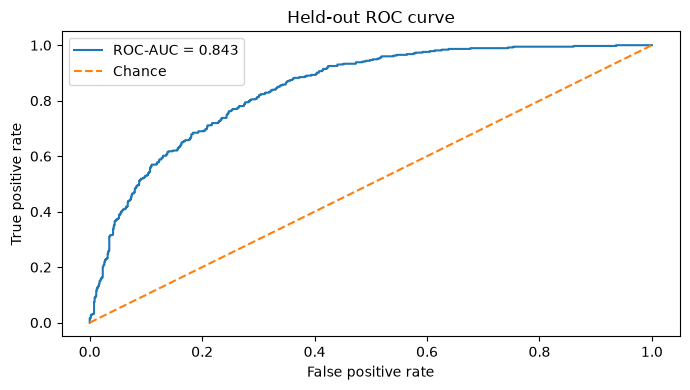

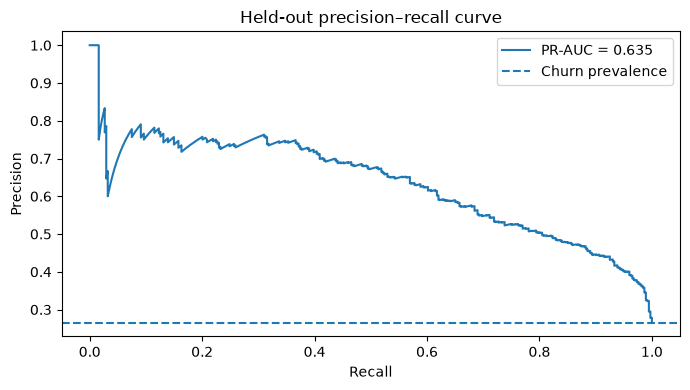

In [20]:
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay, classification_report, roc_curve, precision_recall_curve

test_probs=selected_model.predict_proba(X_test)[:,1]
test_pred=(test_probs>=selected_threshold).astype(int)
metrics = {
    'accuracy':accuracy_score(y_test,test_pred),
    'precision':precision_score(y_test,test_pred,zero_division=0),
    'recall':recall_score(y_test,test_pred,zero_division=0),
    'f1':f1_score(y_test,test_pred,zero_division=0),
    'roc_auc':roc_auc_score(y_test,test_probs),
    'pr_auc':average_precision_score(y_test,test_probs)
}
print('Final held-out test metrics:', {k:round(v,4) for k,v in metrics.items()})
print(classification_report(y_test,test_pred,zero_division=0))
ConfusionMatrixDisplay.from_predictions(y_test,test_pred,display_labels=['No churn','Churn'],cmap='Blues',values_format='d')
plt.title(f'{selected_name} — held-out test')
plt.tight_layout();plt.show()

fpr,tpr,_=roc_curve(y_test,test_probs)
precision,recall,_=precision_recall_curve(y_test,test_probs)
plt.figure(figsize=(7,4));plt.plot(fpr,tpr,label=f'ROC-AUC = {metrics["roc_auc"]:.3f}');plt.plot([0,1],[0,1],'--',label='Chance');plt.xlabel('False positive rate');plt.ylabel('True positive rate');plt.legend();plt.title('Held-out ROC curve');plt.tight_layout();plt.show()
plt.figure(figsize=(7,4));plt.plot(recall,precision,label=f'PR-AUC = {metrics["pr_auc"]:.3f}');plt.axhline(y_test.mean(),linestyle='--',label='Churn prevalence');plt.xlabel('Recall');plt.ylabel('Precision');plt.legend();plt.title('Held-out precision–recall curve');plt.tight_layout();plt.show()

## 9. Retention targeting — illustrative scenario, not estimated uplift
Assume each targeted customer costs ₹500, retained customer value is ₹5,000, and **incremental retention effectiveness is 20%**, measured independently (e.g. with a randomized experiment). If these assumptions held uniformly and churn probabilities were calibrated, illustrative expected net benefit is `p_churn × 0.20 × 5000 − 500`. These are not empirically validated uplift estimates.

For policy design use **validation** predictions, not the held-out test. Equal offer costs permit sorting by expected net benefit; unequal costs require constrained optimization.

In [21]:
offer_cost=500.0
customer_value=5000.0
assumed_incremental_effect=0.20
campaign_budget=15000.0  # illustrative total budget
max_offers=int(campaign_budget//offer_cost)

campaign = pd.DataFrame({'customerID':df.loc[X_val.index,'customerID'].to_numpy(), 'predicted_churn_probability':val_probs})
campaign['expected_gross_benefit']=campaign['predicted_churn_probability']*assumed_incremental_effect*customer_value
campaign['expected_net_benefit']=campaign['expected_gross_benefit']-offer_cost
eligible=campaign.loc[campaign.expected_net_benefit>0].sort_values('expected_net_benefit',ascending=False)
selected_customers=eligible.head(max_offers).copy()
print('Campaign budget:',campaign_budget,'Max offers:',max_offers)
print('Selected customers:',len(selected_customers))
print('Total spend:',len(selected_customers)*offer_cost)
print('Illustrative total expected net benefit:',round(selected_customers.expected_net_benefit.sum(),2))
display(selected_customers.head(10).round(2))

Campaign budget: 15000.0 Max offers: 30
Selected customers: 30
Total spend: 15000.0
Illustrative total expected net benefit: 8651.0


,customerID,predicted_churn_probability,expected_gross_benefit,expected_net_benefit
868,5567-WSELE,0.84,842.39,342.39
456,3049-SOLAY,0.83,826.44,326.44
584,4822-RVYBB,0.82,820.46,320.46
79,0781-LKXBR,0.82,816.55,316.55
230,2446-BEGGB,0.81,814.38,314.38
221,4695-WJZUE,0.81,813.02,313.02
29,3988-RQIXO,0.81,810.27,310.27
869,4912-PIGUY,0.81,810.20,310.20
346,3489-HHPFY,0.80,802.13,302.13
1222,6521-YYTYI,0.80,799.00,299.00


## 10. Executive summary, limitations and next steps

**What this analysis establishes:** Descriptive differences in observed churn by contract and tenure, a reproducible holdout evaluation for churn-risk ranking, and a *scenario-based* retention selection policy.

**Limitations:** Historical customer snapshots can contain temporal or selection effects; predictive probability calibration must be checked; observed churn differences do not prove causation; the assumed 20% campaign effectiveness is not measured from this dataset; test data must remain untouched for selection. Further work should use time-aware evaluation if timestamps become available, treatment/control experiments for uplift, subgroup fairness checks, and monitoring after deployment.

**Project note:** A 20% retention assumption, ₹500 offer cost and ₹5,000 customer value are hypothetical, not IBM dataset facts.

In [22]:
print(f'Final model: {selected_name}')
print(f'Selected threshold on validation: {selected_threshold:.2f}')
print('Held-out test ROC-AUC:',round(metrics['roc_auc'],3),'PR-AUC:',round(metrics['pr_auc'],3))
print('Held-out recall:',round(metrics['recall'],3),'precision:',round(metrics['precision'],3))
print('Illustrative campaign customers selected:',len(selected_customers))

Final model: Logistic Regression
Selected threshold on validation: 0.35
Held-out test ROC-AUC: 0.843 PR-AUC: 0.635
Held-out recall: 0.711 precision: 0.547
Illustrative campaign customers selected: 30
